In [3]:


import sys
import warnings
import calendar

import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')

pd.set_option('display.width', 95)
pd.set_option('display.max_columns', 30)

sns.set_style('whitegrid')

print('Python     :', sys.version.split()[0])
print('pandas     :', pd.__version__)
print('numpy      :', np.__version__)
print('matplotlib :', matplotlib.__version__)
print('seaborn    :', sns.__version__)



Python     : 3.13.16
pandas     : 2.2.3
numpy      : 2.1.3
matplotlib : 3.10.0
seaborn    : 0.13.2


In [5]:

# 3. LOAD DATASET

df = pd.read_excel('Tailor_Shop_Synthetic_Dataset_500.xlsx')

print('Dataset shape:', df.shape)
print()

df.info()

Dataset shape: (500, 18)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 18 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   Order_ID         500 non-null    object        
 1   Customer_Name    500 non-null    object        
 2   Age              500 non-null    int64         
 3   Gender           500 non-null    object        
 4   Contact_Number   500 non-null    int64         
 5   Garment_Type     500 non-null    object        
 6   Fabric_Type      500 non-null    object        
 7   Quantity         500 non-null    int64         
 8   Order_Date       500 non-null    datetime64[ns]
 9   Delivery_Date    500 non-null    datetime64[ns]
 10  Stitching_Cost   500 non-null    int64         
 11  Alteration_Cost  500 non-null    int64         
 12  Total_Amount     500 non-null    int64         
 13  Payment_Method   500 non-null    object        
 14  Payment_Status  

In [6]:

# 4. CHECK MISSING VALUES AND DUPLICATES


print("Missing Values:")
print(df.isnull().sum())

print()

print('Duplicate rows      :', df.duplicated().sum())
print('Duplicate Order_IDs :', df['Order_ID'].duplicated().sum())


Missing Values:
Order_ID           0
Customer_Name      0
Age                0
Gender             0
Contact_Number     0
Garment_Type       0
Fabric_Type        0
Quantity           0
Order_Date         0
Delivery_Date      0
Stitching_Cost     0
Alteration_Cost    0
Total_Amount       0
Payment_Method     0
Payment_Status     0
Order_Status       0
Tailor_Assigned    0
Customer_Rating    0
dtype: int64

Duplicate rows      : 0
Duplicate Order_IDs : 0


In [7]:

# 5. VALIDATE DATA VALUES


print(
    'Total_Amount = Stitching_Cost + Alteration_Cost :',
    (df['Stitching_Cost'] + df['Alteration_Cost'] == df['Total_Amount']).all()
)

print(
    'Delivery_Date is never before Order_Date        :',
    (df['Delivery_Date'] >= df['Order_Date']).all()
)

print(
    'Customer_Rating is always between 1 and 5       :',
    df['Customer_Rating'].between(1, 5).all()
)

print(
    'Quantity is always between 1 and 3              :',
    df['Quantity'].between(1, 3).all()
)

print(
    'Every contact number has 10 digits              :',
    (df['Contact_Number'].astype(str).str.len() == 10).all()
)

print(
    'Age range                                       :',
    df['Age'].min(), 'to', df['Age'].max()
)

print(
    'Order dates                                     :',
    df['Order_Date'].min().date(), 'to', df['Order_Date'].max().date()
)

Total_Amount = Stitching_Cost + Alteration_Cost : True
Delivery_Date is never before Order_Date        : True
Customer_Rating is always between 1 and 5       : True
Quantity is always between 1 and 3              : True
Every contact number has 10 digits              : True
Age range                                       : 18 to 60
Order dates                                     : 2026-01-01 to 2026-09-30


In [8]:

# 6. BUSINESS LOGIC CHECK


last_order = df['Order_Date'].max()

delivered_late = df[
    (df['Order_Status'] == 'Delivered') &
    (df['Delivery_Date'] > last_order)
]

cancelled_paid = df[
    (df['Order_Status'] == 'Cancelled') &
    (df['Payment_Status'] == 'Paid')
]

names_many_phones = (
    df.groupby('Customer_Name')['Contact_Number'].nunique() > 1
).sum()

print('Last order date in the data                         :', last_order.date())
print('Orders marked Delivered with a later delivery date :', len(delivered_late))
print('Cancelled orders whose payment status is Paid      :', len(cancelled_paid))
print('Unique customer names                              :', df['Customer_Name'].nunique())
print('Unique contact numbers                             :', df['Contact_Number'].nunique())
print('Customer names linked to more than one phone      :', names_many_phones)

Last order date in the data                         : 2026-09-30
Orders marked Delivered with a later delivery date : 8
Cancelled orders whose payment status is Paid      : 16
Unique customer names                              : 311
Unique contact numbers                             : 500
Customer names linked to more than one phone      : 132


In [9]:

# 7. REMOVE PERSONAL INFORMATION


df = df.drop(columns=['Customer_Name', 'Contact_Number'])


# 8. CREATE NEW FEATURES

df['Delivery_Days'] = (
    df['Delivery_Date'] - df['Order_Date']
).dt.days

df['Month_No'] = df['Order_Date'].dt.month

df['Unit_Price'] = (
    df['Stitching_Cost'] / df['Quantity']
)

df['Age_Group'] = pd.cut(
    df['Age'],
    bins=[17, 25, 35, 45, 60],
    labels=['18-25', '26-35', '36-45', '46-60']
)

df['Has_Alteration'] = np.where(
    df['Alteration_Cost'] > 0,
    'Yes',
    'No'
)

print(df.head(3).T)
print()
print('New shape:', df.shape)

                                   0                    1                    2
Order_ID                        T001                 T002                 T003
Age                               23                   18                   47
Gender                        Female                 Male                 Male
Garment_Type                  Pajama             Sherwani                Kurti
Fabric_Type                   Cotton            Georgette                 Silk
Quantity                           2                    1                    1
Order_Date       2026-02-27 00:00:00  2026-04-30 00:00:00  2026-03-21 00:00:00
Delivery_Date    2026-03-01 00:00:00  2026-05-06 00:00:00  2026-03-26 00:00:00
Stitching_Cost                   600                 3250                  500
Alteration_Cost                    0                    0                   50
Total_Amount                     600                 3250                  550
Payment_Method                  Cash        Bank Tra

In [10]:

# 9. DESCRIPTIVE STATISTICS


num_cols = [
    'Age',
    'Quantity',
    'Stitching_Cost',
    'Alteration_Cost',
    'Total_Amount',
    'Delivery_Days',
    'Customer_Rating'
]

print(df[num_cols].describe().T.round(2))

                 count     mean      std    min    25%     50%     75%      max
Age              500.0    38.97    12.34   18.0   29.0    38.0    49.0     60.0
Quantity         500.0     1.96     0.81    1.0    1.0     2.0     3.0      3.0
Stitching_Cost   500.0  1978.10  1812.12  250.0  750.0  1400.0  2500.0  10500.0
Alteration_Cost  500.0    73.00    76.31    0.0    0.0    50.0   150.0    200.0
Total_Amount     500.0  2051.10  1820.91  250.0  850.0  1450.0  2550.0  10600.0
Delivery_Days    500.0     5.97     2.59    2.0    4.0     6.0     8.0     10.0
Customer_Rating  500.0     3.12     1.44    1.0    2.0     3.0     4.0      5.0


In [11]:

# 10. KEY BUSINESS NUMBERs

active = df[df['Order_Status'] != 'Cancelled']

print('Total orders                   :', len(df))
print('Cancelled orders               :', (df['Order_Status'] == 'Cancelled').sum())

print(
    'Cancellation rate (%)          :',
    round((df['Order_Status'] == 'Cancelled').mean() * 100, 1)
)

print(
    'Total order value, all orders : Rs.',
    f"{df['Total_Amount'].sum():,}"
)

print(
    'Total order value, no cancelled: Rs.',
    f"{active['Total_Amount'].sum():,}"
)

print(
    'Average order value            : Rs.',
    round(df['Total_Amount'].mean(), 2)
)

print(
    'Average customer rating        :',
    round(df['Customer_Rating'].mean(), 2)
)

print(
    'Average delivery time (days)   :',
    round(df['Delivery_Days'].mean(), 1)
)

print(
    'Orders fully paid (%)          :',
    round((df['Payment_Status'] == 'Paid').mean() * 100, 1)
)

Total orders                   : 500
Cancelled orders               : 25
Cancellation rate (%)          : 5.0
Total order value, all orders : Rs. 1,025,550
Total order value, no cancelled: Rs. 970,000
Average order value            : Rs. 2051.1
Average customer rating        : 3.12
Average delivery time (days)   : 6.0
Orders fully paid (%)          : 73.6


In [12]:

# 11. GARMENT AND FABRIC POPULARITY


for col in ['Garment_Type', 'Fabric_Type']:

    counts = df[col].value_counts()

    print(pd.DataFrame({
        'Orders': counts,
        'Percent': (counts / len(df) * 100).round(1)
    }))

    print()

              Orders  Percent
Garment_Type                 
Kurti             50     10.0
Shirt             48      9.6
Kurta             47      9.4
Blouse            43      8.6
Sherwani          42      8.4
Dress             41      8.2
Salwar Suit       40      8.0
Waistcoat         40      8.0
Pant              39      7.8
Saree Blouse      38      7.6
Lehenga           37      7.4
Pajama            35      7.0

             Orders  Percent
Fabric_Type                 
Rayon            62     12.4
Chiffon          59     11.8
Silk             51     10.2
Denim            50     10.0
Suiting          50     10.0
Linen            48      9.6
Georgette        47      9.4
Polyester        46      9.2
Velvet           44      8.8
Cotton           43      8.6



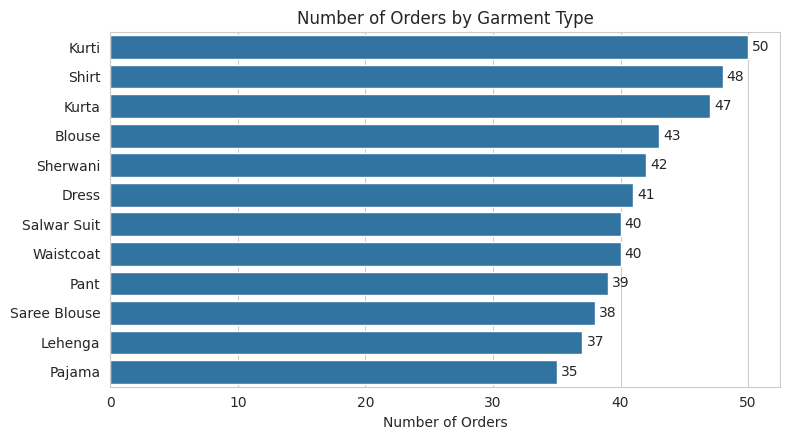

In [13]:
plt.figure(figsize=(8, 4.5))

ax = sns.countplot(
    data=df,
    y='Garment_Type',
    order=df['Garment_Type'].value_counts().index
)

ax.bar_label(ax.containers[0], padding=3)

plt.title('Number of Orders by Garment Type')
plt.xlabel('Number of Orders')
plt.ylabel('')

plt.tight_layout()
plt.show()

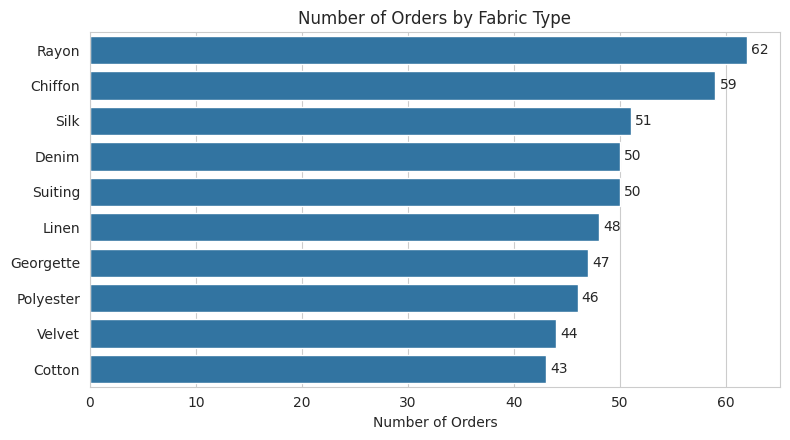

In [14]:
plt.figure(figsize=(8, 4.5))

ax = sns.countplot(
    data=df,
    y='Fabric_Type',
    order=df['Fabric_Type'].value_counts().index
)

ax.bar_label(ax.containers[0], padding=3)

plt.title('Number of Orders by Fabric Type')
plt.xlabel('Number of Orders')
plt.ylabel('')

plt.tight_layout()
plt.show()

In [15]:

# 12. ORDER AND PAYMENT ANALYSIS


for col in [
    'Order_Status',
    'Payment_Status',
    'Payment_Method'
]:

    counts = df[col].value_counts()

    print(pd.DataFrame({
        'Orders': counts,
        'Percent': (counts / len(df) * 100).round(1)
    }))

    print()

              Orders  Percent
Order_Status                 
Delivered        281     56.2
In Progress      122     24.4
Ready             72     14.4
Cancelled         25      5.0

                Orders  Percent
Payment_Status                 
Paid               368     73.6
Partially Paid      67     13.4
Pending             65     13.0

                Orders  Percent
Payment_Method                 
Cash               144     28.8
UPI                123     24.6
Bank Transfer      119     23.8
Card               114     22.8



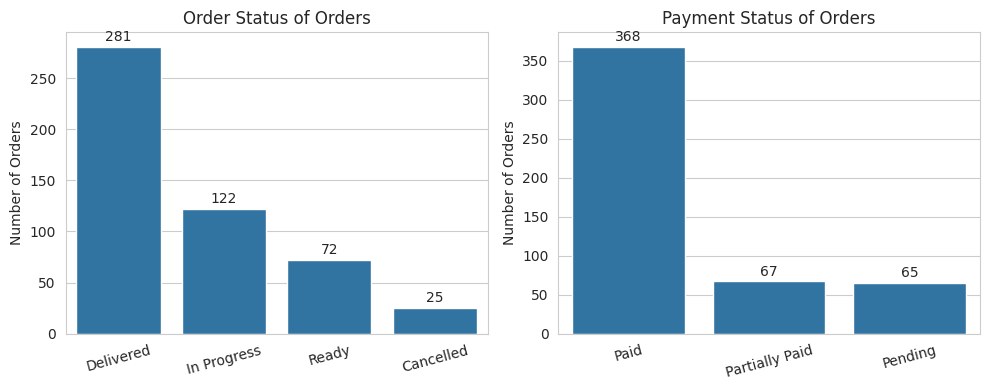

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, col in zip(
    axes,
    ['Order_Status', 'Payment_Status']
):

    sns.countplot(
        data=df,
        x=col,
        order=df[col].value_counts().index,
        ax=ax
    )

    ax.bar_label(ax.containers[0], padding=2)

    ax.set_title(col.replace('_', ' ') + ' of Orders')
    ax.set_xlabel('')
    ax.set_ylabel('Number of Orders')

    ax.tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.show()

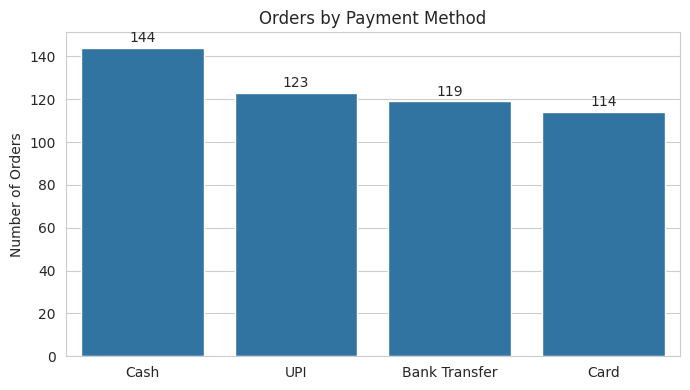

In [17]:
plt.figure(figsize=(7, 4))

ax = sns.countplot(
    data=df,
    x='Payment_Method',
    order=df['Payment_Method'].value_counts().index
)

ax.bar_label(ax.containers[0], padding=2)

plt.title('Orders by Payment Method')
plt.xlabel('')
plt.ylabel('Number of Orders')

plt.tight_layout()
plt.show()

In [18]:

# 13. PAYMENT METHOD VS PAYMENT STATUS


ct = pd.crosstab(
    df['Payment_Method'],
    df['Payment_Status']
)

print(ct)

print()

print('Row percentages:')

print(
    (
        pd.crosstab(
            df['Payment_Method'],
            df['Payment_Status'],
            normalize='index'
        ) * 100
    ).round(1)
)

Payment_Status  Paid  Partially Paid  Pending
Payment_Method                               
Bank Transfer     87              15       17
Card              78              20       16
Cash             110              17       17
UPI               93              15       15

Row percentages:
Payment_Status  Paid  Partially Paid  Pending
Payment_Method                               
Bank Transfer   73.1            12.6     14.3
Card            68.4            17.5     14.0
Cash            76.4            11.8     11.8
UPI             75.6            12.2     12.2


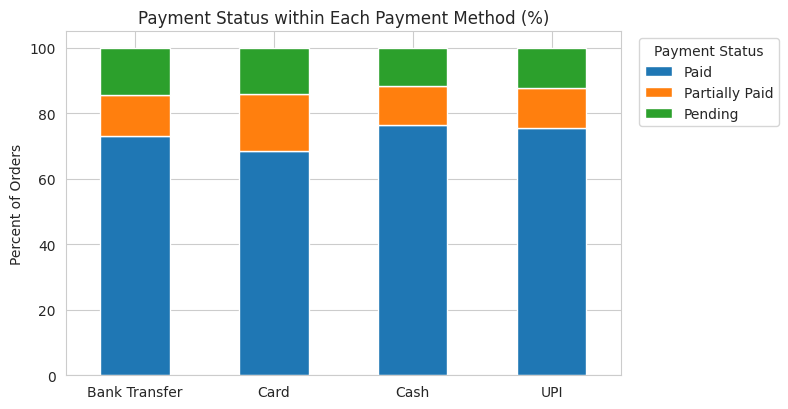

In [19]:
pd.crosstab(
    df['Payment_Method'],
    df['Payment_Status'],
    normalize='index'
).mul(100).plot(
    kind='bar',
    stacked=True,
    figsize=(8, 4.2)
)

plt.title('Payment Status within Each Payment Method (%)')
plt.xlabel('')
plt.ylabel('Percent of Orders')
plt.xticks(rotation=0)

plt.legend(
    title='Payment Status',
    bbox_to_anchor=(1.02, 1),
    loc='upper left'
)

plt.tight_layout()
plt.show()

In [20]:

# 14. GENDER AND GARMENT CHOICE


print(df['Gender'].value_counts())

print()

print(
    pd.crosstab(
        df['Garment_Type'],
        df['Gender']
    )
)

Gender
Female    255
Male      245
Name: count, dtype: int64

Gender        Female  Male
Garment_Type              
Blouse            22    21
Dress             21    20
Kurta             19    28
Kurti             27    23
Lehenga           14    23
Pajama            18    17
Pant              22    17
Salwar Suit       24    16
Saree Blouse      20    18
Sherwani          24    18
Shirt             25    23
Waistcoat         19    21


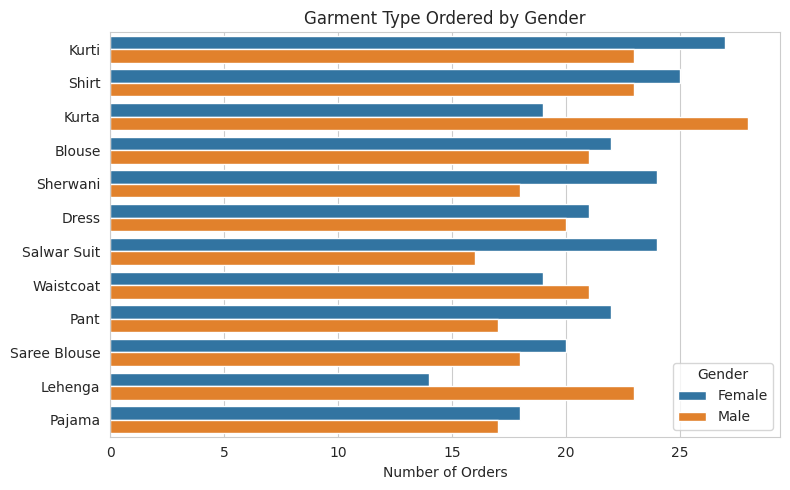

In [21]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    y='Garment_Type',
    hue='Gender',
    order=df['Garment_Type'].value_counts().index
)

plt.title('Garment Type Ordered by Gender')
plt.xlabel('Number of Orders')
plt.ylabel('')

plt.tight_layout()
plt.show()

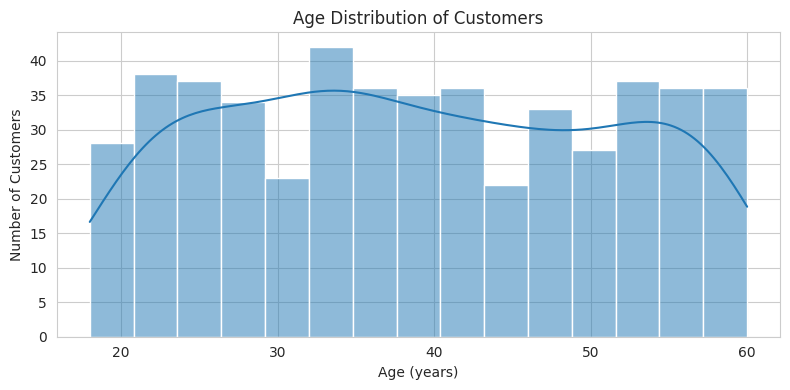

In [22]:

# 15. CUSTOMER AGE ANALYis

plt.figure(figsize=(8, 4))

sns.histplot(
    df['Age'],
    bins=15,
    kde=True
)

plt.title('Age Distribution of Customers')
plt.xlabel('Age (years)')
plt.ylabel('Number of Customers')

plt.tight_layout()
plt.show()

In [23]:
age_summary = (
    df.groupby('Age_Group', observed=True)['Total_Amount']
    .agg(['count', 'mean'])
    .round(2)
)

age_summary.columns = [
    'Orders',
    'Avg_Order_Value'
]

print(age_summary)

           Orders  Avg_Order_Value
Age_Group                         
18-25          89          1951.12
26-35         130          2118.08
36-45         112          2102.23
46-60         169          2018.34


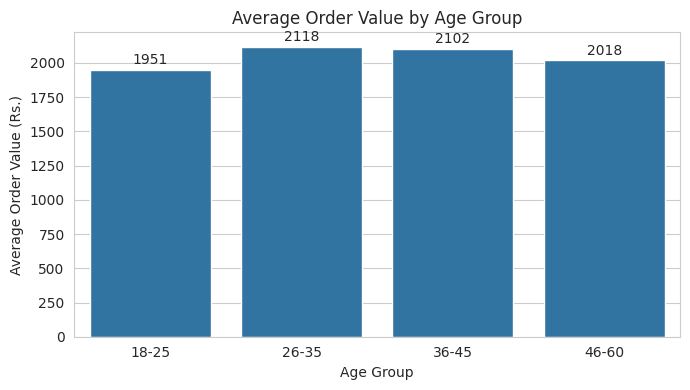

In [25]:
plt.figure(figsize=(7, 4))

ax = sns.barplot(
    x=age_summary.index,
    y=age_summary['Avg_Order_Value']
)

ax.bar_label(
    ax.containers[0],
    fmt='%.0f',
    padding=2
)

plt.title('Average Order Value by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Average Order Value (Rs.)')

plt.tight_layout()
plt.show()

In [26]:

# 16. REVENUE AND ORDER VALUE BY GARMENT


rev = (
    active.groupby('Garment_Type')['Total_Amount']
    .agg(['count', 'sum', 'mean'])
    .round(0)
)

rev.columns = [
    'Orders',
    'Total_Value',
    'Avg_Order_Value'
]

rev = rev.sort_values(
    'Total_Value',
    ascending=False
)

print(rev.astype(int))

              Orders  Total_Value  Avg_Order_Value
Garment_Type                                      
Sherwani          39       220850             5663
Lehenga           35       142900             4083
Dress             40       102650             2566
Salwar Suit       37        93800             2535
Waistcoat         38        78550             2067
Kurti             49        64300             1312
Blouse            41        58400             1424
Saree Blouse      35        54000             1543
Kurta             44        49150             1117
Shirt             45        40900              909
Pant              39        40750             1045
Pajama            33        23750              720


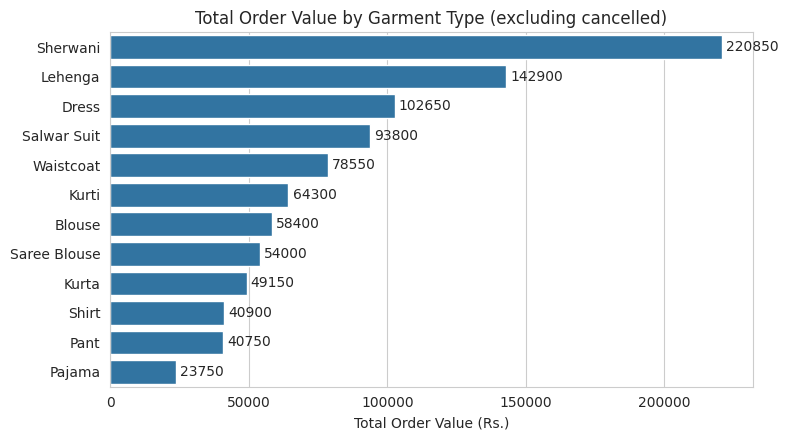

In [27]:
plt.figure(figsize=(8, 4.5))

ax = sns.barplot(
    x=rev['Total_Value'],
    y=rev.index
)

ax.bar_label(
    ax.containers[0],
    fmt='%.0f',
    padding=3
)

plt.title(
    'Total Order Value by Garment Type (excluding cancelled)'
)

plt.xlabel('Total Order Value (Rs.)')
plt.ylabel('')

plt.tight_layout()
plt.show()

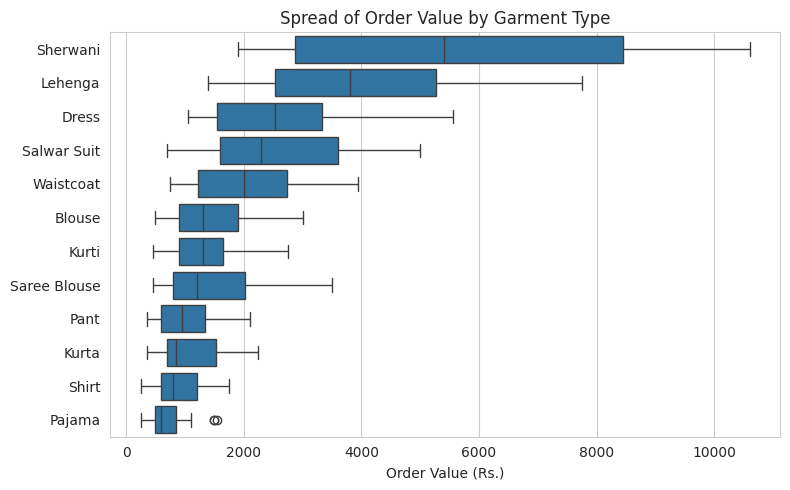

In [28]:
order_by_median = (
    active.groupby('Garment_Type')['Total_Amount']
    .median()
    .sort_values(ascending=False)
    .index
)

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=active,
    y='Garment_Type',
    x='Total_Amount',
    order=order_by_median
)

plt.title('Spread of Order Value by Garment Type')
plt.xlabel('Order Value (Rs.)')
plt.ylabel('')

plt.tight_layout()
plt.show()

In [29]:

# 17. EFFECT OF FABRIC ON PRICE


df['Price_Index'] = (
    df['Unit_Price'] /
    df.groupby('Garment_Type')['Unit_Price'].transform('mean')
)

fabric = (
    df.groupby('Fabric_Type')
    .agg(
        Orders=('Order_ID', 'count'),
        Avg_Unit_Price=('Unit_Price', 'mean'),
        Price_Index=('Price_Index', 'mean')
    )
    .round(2)
)

fabric = fabric.sort_values(
    'Price_Index',
    ascending=False
)

print(fabric)

             Orders  Avg_Unit_Price  Price_Index
Fabric_Type                                     
Suiting          50          799.00         1.07
Velvet           44         1064.77         1.03
Rayon            62         1068.55         1.02
Polyester        46          898.91         1.02
Georgette        47         1295.74         1.02
Chiffon          59          955.08         1.01
Silk             51          921.57         0.98
Cotton           43          825.58         0.97
Linen            48         1077.08         0.96
Denim            50          997.00         0.92


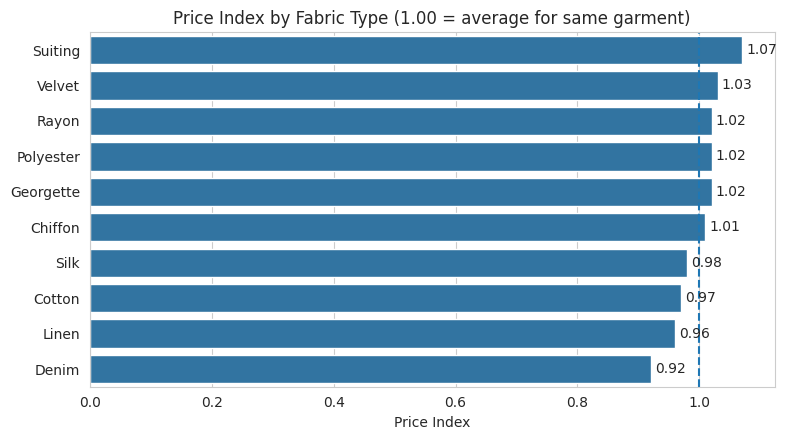

In [30]:
plt.figure(figsize=(8, 4.5))

ax = sns.barplot(
    x=fabric['Price_Index'],
    y=fabric.index
)

ax.bar_label(
    ax.containers[0],
    fmt='%.2f',
    padding=3
)

plt.axvline(
    1,
    linestyle='--'
)

plt.title(
    'Price Index by Fabric Type (1.00 = average for same garment)'
)

plt.xlabel('Price Index')
plt.ylabel('')

plt.tight_layout()
plt.show()

In [31]:

# 18. QUANTITY AND ORDER VALUE


qty = (
    df.groupby('Quantity')['Total_Amount']
    .agg(['count', 'mean'])
    .round(2)
)

qty.columns = [
    'Orders',
    'Avg_Order_Value'
]

print(qty)

          Orders  Avg_Order_Value
Quantity                         
1            175          1038.57
2            169          1964.79
3            156          3280.45


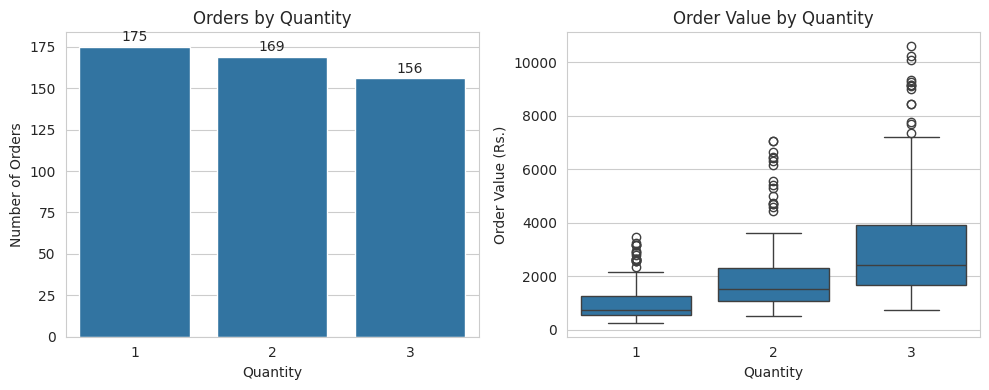

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

sns.countplot(
    data=df,
    x='Quantity',
    ax=axes[0]
)

axes[0].bar_label(
    axes[0].containers[0],
    padding=2
)

axes[0].set_title('Orders by Quantity')
axes[0].set_ylabel('Number of Orders')


sns.boxplot(
    data=df,
    x='Quantity',
    y='Total_Amount',
    ax=axes[1]
)

axes[1].set_title('Order Value by Quantity')
axes[1].set_ylabel('Order Value (Rs.)')

plt.tight_layout()
plt.show()

In [33]:


monthly = (
    active.groupby('Month_No')
    .agg(
        Orders=('Order_ID', 'count'),
        Order_Value=('Total_Amount', 'sum')
    )
)

monthly.index = [
    calendar.month_abbr[m]
    for m in monthly.index
]

print(monthly)

     Orders  Order_Value
Jan      57       114450
Feb      62       139600
Mar      51        99150
Apr      46        86300
May      46       121350
Jun      56        97400
Jul      61       138650
Aug      44        75900
Sep      52        97200


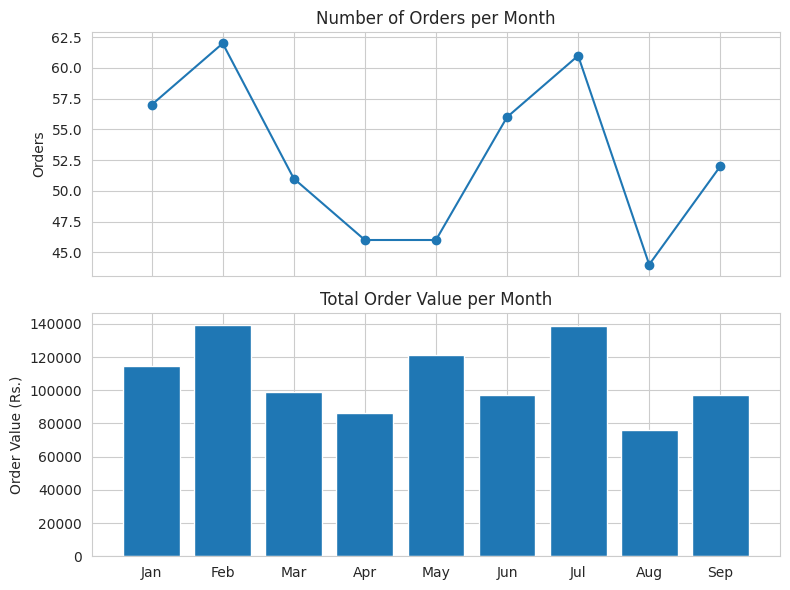

In [34]:
fig, axes = plt.subplots(
    2, 1,
    figsize=(8, 6),
    sharex=True
)

axes[0].plot(
    monthly.index,
    monthly['Orders'],
    marker='o'
)

axes[0].set_title('Number of Orders per Month')
axes[0].set_ylabel('Orders')

axes[1].bar(
    monthly.index,
    monthly['Order_Value']
)

axes[1].set_title('Total Order Value per Month')
axes[1].set_ylabel('Order Value (Rs.)')

plt.tight_layout()
plt.show()

In [35]:

# 20. ALTERATION ANALYSIS


with_alt = df[
    df['Alteration_Cost'] > 0
]

print(
    'Orders with alteration (%):',
    round(len(with_alt) / len(df) * 100, 1)
)

print(
    'Average alteration charge : Rs.',
    round(with_alt['Alteration_Cost'].mean(), 1)
)

print()

print(
    df['Alteration_Cost']
    .value_counts()
    .sort_index()
)

Orders with alteration (%): 56.6
Average alteration charge : Rs. 129.0

Alteration_Cost
0      217
50      62
100     71
150     74
200     76
Name: count, dtype: int64


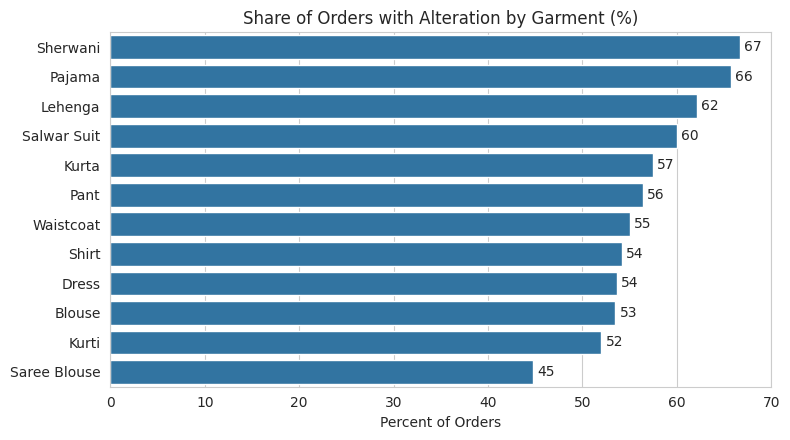

In [36]:
alt_share = (
    (df['Has_Alteration'] == 'Yes')
    .groupby(df['Garment_Type'])
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

plt.figure(figsize=(8, 4.5))

ax = sns.barplot(
    x=alt_share.values,
    y=alt_share.index
)

ax.bar_label(
    ax.containers[0],
    fmt='%.0f',
    padding=3
)

plt.title(
    'Share of Orders with Alteration by Garment (%)'
)

plt.xlabel('Percent of Orders')
plt.ylabel('')

plt.tight_layout()
plt.show()

In [37]:

# 21. DELIVERY TIME ANALYSIS


print(
    df['Delivery_Days']
    .describe()
    .round(2)
)

print()

print(
    df.groupby('Garment_Type')['Delivery_Days']
    .mean()
    .round(2)
    .sort_values()
)

count    500.00
mean       5.97
std        2.59
min        2.00
25%        4.00
50%        6.00
75%        8.00
max       10.00
Name: Delivery_Days, dtype: float64

Garment_Type
Salwar Suit     5.05
Kurta           5.17
Sherwani        5.64
Saree Blouse    5.95
Shirt           6.04
Pant            6.05
Pajama          6.14
Lehenga         6.22
Dress           6.29
Blouse          6.33
Kurti           6.38
Waistcoat       6.45
Name: Delivery_Days, dtype: float64


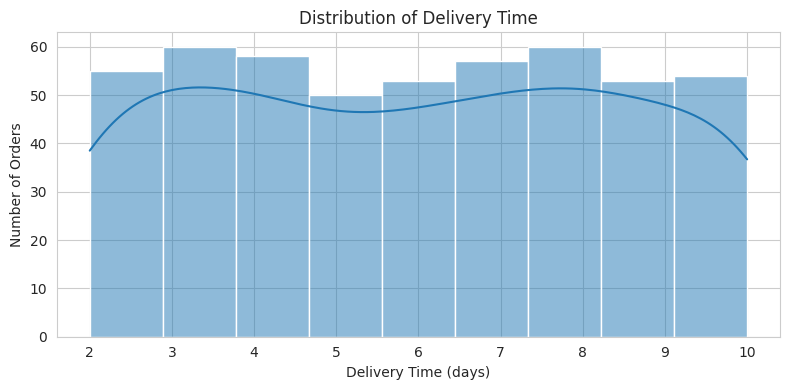

In [38]:
plt.figure(figsize=(8, 4))

sns.histplot(
    df['Delivery_Days'],
    bins=9,
    kde=True
)

plt.title('Distribution of Delivery Time')
plt.xlabel('Delivery Time (days)')
plt.ylabel('Number of Orders')

plt.tight_layout()
plt.show()

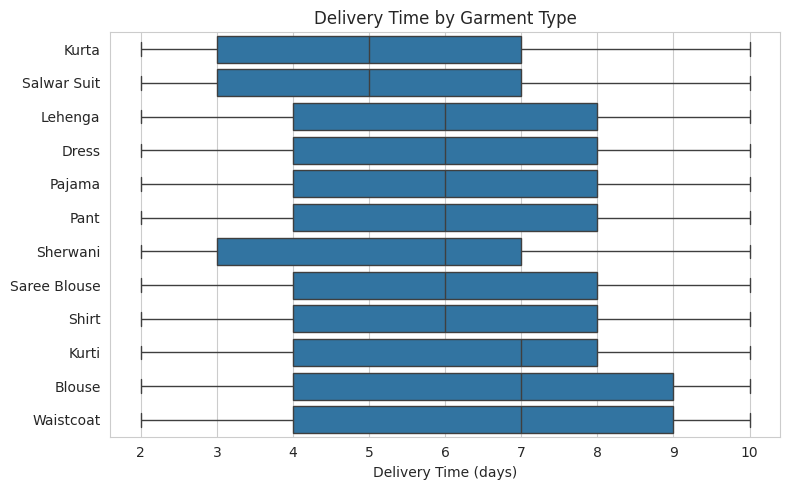

In [39]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    y='Garment_Type',
    x='Delivery_Days',
    order=df.groupby(
        'Garment_Type'
    )['Delivery_Days'].median().sort_values().index
)

plt.title('Delivery Time by Garment Type')
plt.xlabel('Delivery Time (days)')
plt.ylabel('')

plt.tight_layout()
plt.show()

In [40]:

# 22. TAILOR PERFORMANCE


tailor = (
    df.groupby('Tailor_Assigned')
    .agg(
        Orders=('Order_ID', 'count'),
        Avg_Rating=('Customer_Rating', 'mean'),
        Avg_Delivery_Days=('Delivery_Days', 'mean'),
        Order_Value=('Total_Amount', 'sum')
    )
    .round(2)
)

tailor = tailor.sort_values(
    'Orders',
    ascending=False
)

print(tailor)

                 Orders  Avg_Rating  Avg_Delivery_Days  Order_Value
Tailor_Assigned                                                    
Neel                 71        3.24               5.76       159100
Kiran                70        2.94               6.40       145550
Suresh               68        3.00               5.65       119050
Vijay                63        3.17               6.30       124350
Manoj                62        3.21               5.61       108000
Rahul                61        3.11               5.90       134750
Pankaj               55        3.18               6.25       128150
Amit                 50        3.14               5.92       106600


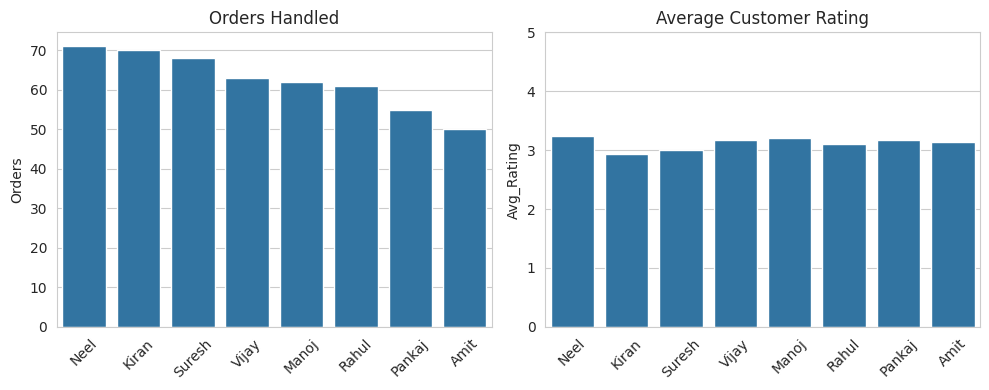

In [41]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(10, 4)
)

sns.barplot(
    x=tailor.index,
    y=tailor['Orders'],
    ax=axes[0]
)

axes[0].set_title('Orders Handled')
axes[0].set_xlabel('')
axes[0].tick_params(
    axis='x',
    rotation=45
)

sns.barplot(
    x=tailor.index,
    y=tailor['Avg_Rating'],
    ax=axes[1]
)

axes[1].set_title('Average Customer Rating')
axes[1].set_xlabel('')
axes[1].set_ylim(0, 5)
axes[1].tick_params(
    axis='x',
    rotation=45
)

plt.tight_layout()
plt.show()

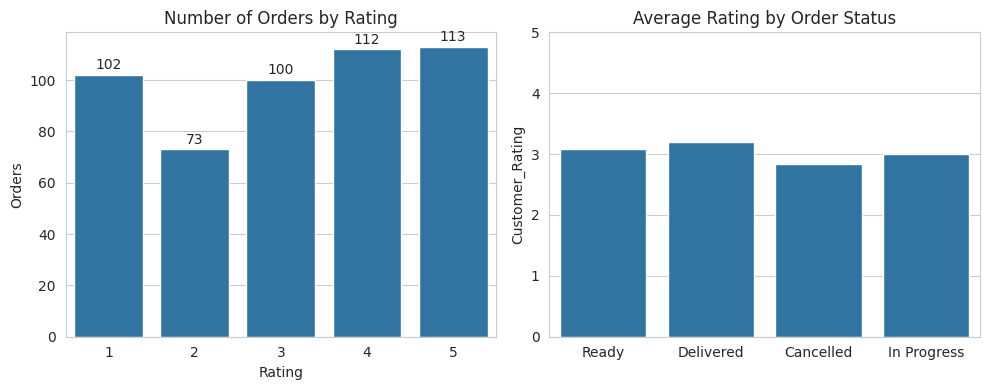

In [42]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(10, 4)
)

sns.countplot(
    data=df,
    x='Customer_Rating',
    ax=axes[0]
)

axes[0].bar_label(
    axes[0].containers[0],
    padding=2
)

axes[0].set_title(
    'Number of Orders by Rating'
)

axes[0].set_xlabel('Rating')
axes[0].set_ylabel('Orders')


sns.barplot(
    data=df,
    x='Order_Status',
    y='Customer_Rating',
    errorbar=None,
    ax=axes[1]
)

axes[1].set_title(
    'Average Rating by Order Status'
)

axes[1].set_xlabel('')
axes[1].set_ylim(0, 5)

plt.tight_layout()
plt.show()

In [43]:

# 24. CORRELATION ANALYSIS


corr_cols = [
    'Age',
    'Quantity',
    'Unit_Price',
    'Total_Amount',
    'Delivery_Days',
    'Customer_Rating'
]

corr = df[corr_cols].corr().round(2)

print(corr)

                  Age  Quantity  Unit_Price  Total_Amount  Delivery_Days  Customer_Rating
Age              1.00     -0.07       -0.01         -0.01          -0.06            -0.07
Quantity        -0.07      1.00        0.06          0.50          -0.02             0.06
Unit_Price      -0.01      0.06        1.00          0.83          -0.03             0.04
Total_Amount    -0.01      0.50        0.83          1.00          -0.06             0.08
Delivery_Days   -0.06     -0.02       -0.03         -0.06           1.00            -0.06
Customer_Rating -0.07      0.06        0.04          0.08          -0.06             1.00


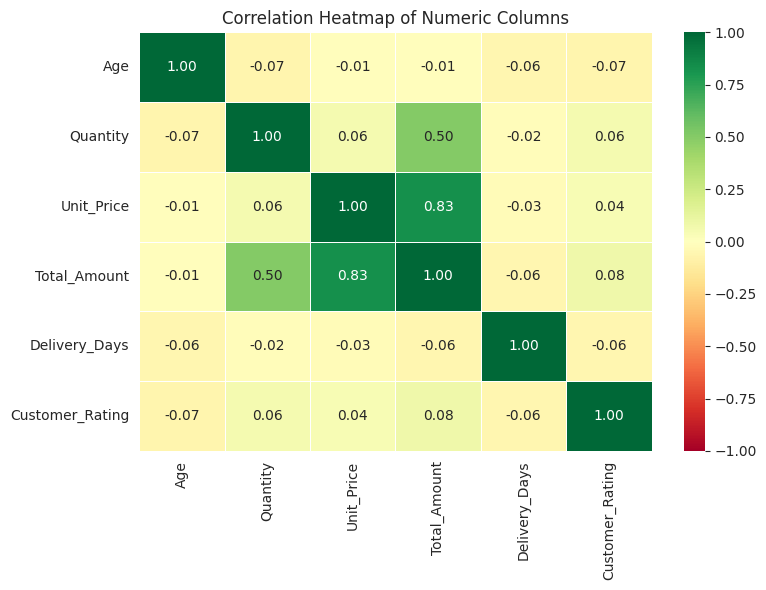

In [44]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    corr,
    annot=True,
    cmap='RdYlGn',
    vmin=-1,
    vmax=1,
    fmt='.2f',
    linewidths=0.5
)

plt.title(
    'Correlation Heatmap of Numeric Columns'
)

plt.tight_layout()
plt.show()

In [45]:

# 25. UNSETTLED PAYMENTS


pay_value = (
    active.groupby('Payment_Status')
    ['Total_Amount']
    .agg(['count', 'sum'])
)

pay_value.columns = [
    'Orders',
    'Order_Value'
]

print(pay_value)

unsettled = active[
    active['Payment_Status'] != 'Paid'
]['Total_Amount'].sum()

print()

print(
    'Order value of active orders not fully paid : Rs.',
    f'{unsettled:,}'
)

print(
    'Share of total active order value (%)        :',
    round(
        unsettled /
        active['Total_Amount'].sum() * 100,
        1
    )
)

                Orders  Order_Value
Payment_Status                     
Paid               352       697800
Partially Paid      64       148350
Pending             59       123850

Order value of active orders not fully paid : Rs. 272,200
Share of total active order value (%)        : 28.1


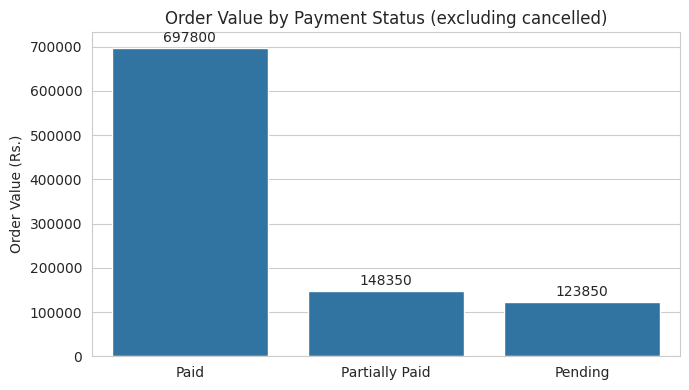

In [46]:
plt.figure(figsize=(7, 4))

ax = sns.barplot(
    x=pay_value.index,
    y=pay_value['Order_Value']
)

ax.bar_label(
    ax.containers[0],
    fmt='%.0f',
    padding=2
)

plt.title(
    'Order Value by Payment Status (excluding cancelled)'
)

plt.xlabel('')
plt.ylabel('Order Value (Rs.)')

plt.tight_layout()
plt.show()

In [47]:

# 26. MACHINE LEARNING LIBRARIES


from sklearn.model_selection import (
    train_test_split,
    cross_val_score,
    KFold,
    StratifiedKFold
)

from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import (
    LinearRegression,
    LogisticRegression
)

from sklearn.ensemble import (
    RandomForestRegressor,
    RandomForestClassifier,
    GradientBoostingRegressor
)

from sklearn.dummy import DummyClassifier

from sklearn.inspection import permutation_importance

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

import sklearn

print('scikit-learn :', sklearn.__version__)

scikit-learn : 1.6.1


In [48]:

# 27. PREPARE REGRESSION DATA


features = [
    'Gender',
    'Age',
    'Garment_Type',
    'Fabric_Type',
    'Quantity'
]

categorical = [
    'Gender',
    'Garment_Type',
    'Fabric_Type'
]

def make_pipeline(model):

    prep = ColumnTransformer(
        [
            (
                'cat',
                OneHotEncoder(
                    handle_unknown='ignore'
                ),
                categorical
            )
        ],
        remainder='passthrough'
    )

    return Pipeline(
        [
            ('prep', prep),
            ('model', model)
        ]
    )


X = df[features]
y = df['Total_Amount']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print('Training set :', X_train.shape)
print('Testing set  :', X_test.shape)

Training set : (400, 5)
Testing set  : (100, 5)


In [49]:

# 28. REGRESSION MODELS


models = {

    'Linear Regression':
        LinearRegression(),

    'Random Forest':
        RandomForestRegressor(
            n_estimators=200,
            random_state=42
        ),

    'Gradient Boosting':
        GradientBoostingRegressor(
            random_state=42
        )
}

kf = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

rows = []
fitted = {}

for name, model in models.items():

    pipe = make_pipeline(model)

    pipe.fit(
        X_train,
        y_train
    )

    pred = pipe.predict(X_test)

    cv_r2 = cross_val_score(
        make_pipeline(model),
        X,
        y,
        cv=kf,
        scoring='r2'
    ).mean()

    rows.append([
        name,
        mean_absolute_error(
            y_test,
            pred
        ),
        np.sqrt(
            mean_squared_error(
                y_test,
                pred
            )
        ),
        r2_score(
            y_test,
            pred
        ),
        cv_r2
    ])

    fitted[name] = pipe


results = pd.DataFrame(
    rows,
    columns=[
        'Model',
        'MAE',
        'RMSE',
        'R2_test',
        'R2_5fold_CV'
    ]
).round(3)

print(
    results.to_string(index=False)
)

            Model     MAE    RMSE  R2_test  R2_5fold_CV
Linear Regression 699.922 948.314    0.795        0.761
    Random Forest 531.195 830.704    0.843        0.826
Gradient Boosting 564.730 885.434    0.821        0.823


In [50]:

# 29. BEST REGRESSION MODEL


best_name = (
    results
    .sort_values(
        'R2_5fold_CV',
        ascending=False
    )
    .iloc[0]['Model']
)

best = fitted[best_name]

pred = best.predict(X_test)

print('Best model               :', best_name)

print(
    'MAE (Rs.)                :',
    round(
        mean_absolute_error(
            y_test,
            pred
        ),
        1
    )
)

print(
    'RMSE (Rs.)               :',
    round(
        np.sqrt(
            mean_squared_error(
                y_test,
                pred
            )
        ),
        1
    )
)

print(
    'R2 on test set           :',
    round(
        r2_score(
            y_test,
            pred
        ),
        3
    )
)

print(
    'MAE as % of mean order   :',
    round(
        mean_absolute_error(
            y_test,
            pred
        )
        / y_test.mean() * 100,
        1
    )
)

Best model               : Random Forest
MAE (Rs.)                : 531.2
RMSE (Rs.)               : 830.7
R2 on test set           : 0.843
MAE as % of mean order   : 25.2


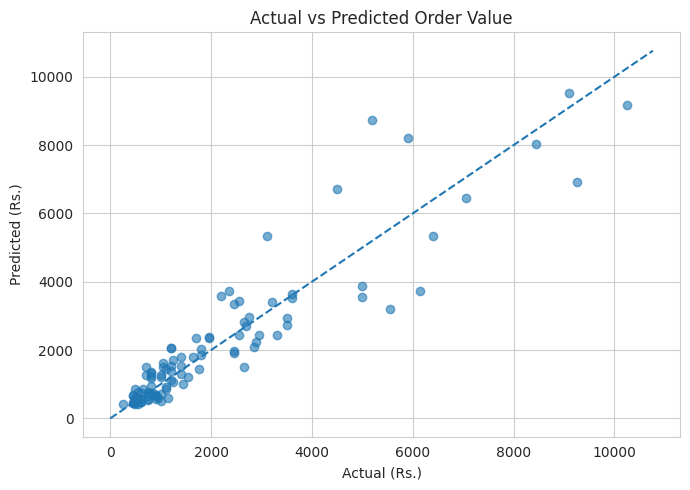

In [51]:

# 30. ACTUAL VS PREDICTED


plt.figure(figsize=(7, 5))

plt.scatter(
    y_test,
    pred,
    alpha=0.6
)

lims = [
    0,
    max(
        y_test.max(),
        pred.max()
    ) * 1.05
]

plt.plot(
    lims,
    lims,
    linestyle='--'
)

plt.title(
    'Actual vs Predicted Order Value'
)

plt.xlabel('Actual (Rs.)')
plt.ylabel('Predicted (Rs.)')

plt.tight_layout()
plt.show()

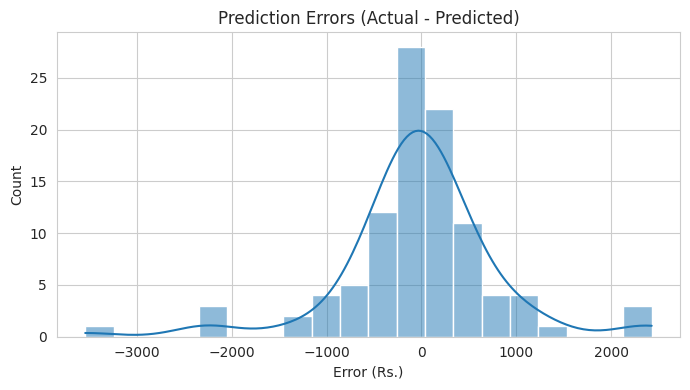

In [52]:
plt.figure(figsize=(7, 4))

sns.histplot(
    y_test - pred,
    bins=20,
    kde=True
)

plt.title(
    'Prediction Errors (Actual - Predicted)'
)

plt.xlabel('Error (Rs.)')

plt.tight_layout()
plt.show()

In [53]:

# 31. PERMUTATION IMPORTANCE


imp = permutation_importance(
    best,
    X_test,
    y_test,
    n_repeats=20,
    random_state=42,
    scoring='r2'
)

importance = pd.Series(
    imp.importances_mean,
    index=X_test.columns
).sort_values(
    ascending=False
)

print(
    'Permutation importance '
    '(drop in R2 when column is shuffled):'
)

print(
    importance.round(4)
)

Permutation importance (drop in R2 when column is shuffled):
Garment_Type    1.0655
Quantity        0.4492
Age             0.0109
Fabric_Type     0.0004
Gender          0.0003
dtype: float64


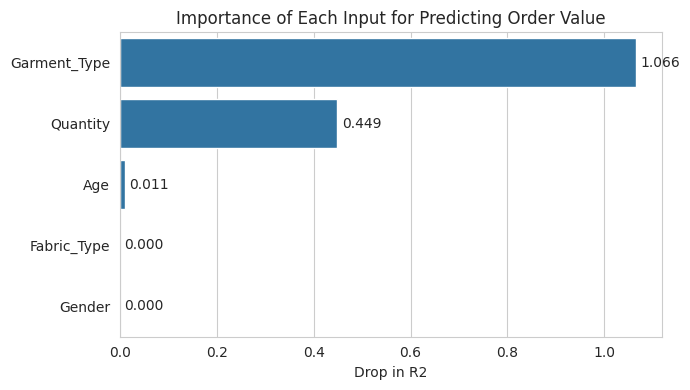

In [54]:
plt.figure(figsize=(7, 4))

ax = sns.barplot(
    x=importance.values,
    y=importance.index
)

ax.bar_label(
    ax.containers[0],
    fmt='%.3f',
    padding=3
)

plt.title(
    'Importance of Each Input for Predicting Order Value'
)

plt.xlabel('Drop in R2')
plt.ylabel('')

plt.tight_layout()
plt.show()

In [55]:

# 32. EXAMPLE PRICE ESTIMATES


samples = pd.DataFrame({

    'Gender': [
        'Male',
        'Female',
        'Female',
        'Male'
    ],

    'Age': [
        30,
        28,
        35,
        40
    ],

    'Garment_Type': [
        'Shirt',
        'Blouse',
        'Lehenga',
        'Sherwani'
    ],

    'Fabric_Type': [
        'Cotton',
        'Silk',
        'Velvet',
        'Silk'
    ],

    'Quantity': [
        1,
        2,
        1,
        1
    ]
})

samples['Predicted_Total_Rs'] = (
    best.predict(
        samples[features]
    ).round(0)
)

print(
    samples.to_string(index=False)
)

Gender  Age Garment_Type Fabric_Type  Quantity  Predicted_Total_Rs
  Male   30        Shirt      Cotton         1               484.0
Female   28       Blouse        Silk         2              1602.0
Female   35      Lehenga      Velvet         1              2439.0
  Male   40     Sherwani        Silk         1              2513.0


In [56]:

# 33. HIGH-VALUE ORDER CLASSIFICATION


threshold = df['Total_Amount'].median()

df['High_Value'] = (
    df['Total_Amount'] > threshold
).astype(int)

print(
    'Median order value (threshold): Rs.',
    threshold
)

print(
    df['High_Value']
    .value_counts()
    .rename({
        1: 'High-value',
        0: 'Normal'
    })
)

Median order value (threshold): Rs. 1450.0
High_Value
Normal        252
High-value    248
Name: count, dtype: int64


In [57]:
yc = df['High_Value']

Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    X,
    yc,
    test_size=0.2,
    random_state=42,
    stratify=yc
)

clf_models = {

    'Logistic Regression':
        LogisticRegression(
            max_iter=1000
        ),

    'Random Forest':
        RandomForestClassifier(
            n_estimators=200,
            random_state=42
        )
}

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

rows = []
fitted_c = {}

for name, model in clf_models.items():

    pipe = make_pipeline(model)

    pipe.fit(
        Xc_train,
        yc_train
    )

    pred_c = pipe.predict(
        Xc_test
    )

    cv_acc = cross_val_score(
        make_pipeline(model),
        X,
        yc,
        cv=skf,
        scoring='accuracy'
    ).mean()

    rows.append([
        name,
        accuracy_score(
            yc_test,
            pred_c
        ),
        precision_score(
            yc_test,
            pred_c
        ),
        recall_score(
            yc_test,
            pred_c
        ),
        f1_score(
            yc_test,
            pred_c
        ),
        cv_acc
    ])

    fitted_c[name] = pipe


clf_results = pd.DataFrame(
    rows,
    columns=[
        'Model',
        'Accuracy',
        'Precision',
        'Recall',
        'F1_score',
        'CV_Accuracy'
    ]
).round(3)

print(
    clf_results.to_string(index=False)
)

              Model  Accuracy  Precision  Recall  F1_score  CV_Accuracy
Logistic Regression      0.90      0.976    0.82     0.891        0.876
      Random Forest      0.87      0.911    0.82     0.863        0.862


In [58]:

# 34. CLASSIFIER EVALUATION


best_clf_name = (
    clf_results
    .sort_values(
        'CV_Accuracy',
        ascending=False
    )
    .iloc[0]['Model']
)

best_clf = fitted_c[best_clf_name]

pred_c = best_clf.predict(
    Xc_test
)

print(
    'Best classifier:',
    best_clf_name
)

cm = confusion_matrix(
    yc_test,
    pred_c
)

print(cm)

print()

print(
    classification_report(
        yc_test,
        pred_c,
        target_names=[
            'Normal',
            'High-value'
        ]
    )
)

Best classifier: Logistic Regression
[[49  1]
 [ 9 41]]

              precision    recall  f1-score   support

      Normal       0.84      0.98      0.91        50
  High-value       0.98      0.82      0.89        50

    accuracy                           0.90       100
   macro avg       0.91      0.90      0.90       100
weighted avg       0.91      0.90      0.90       100



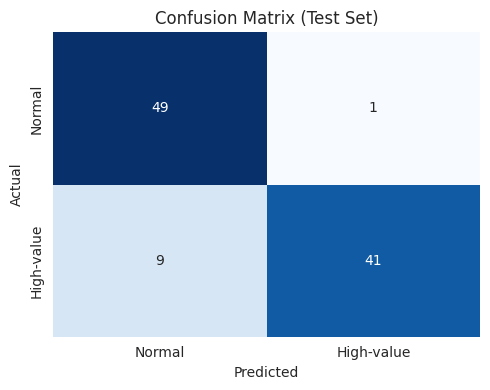

In [59]:
plt.figure(figsize=(5, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    cbar=False,
    xticklabels=[
        'Normal',
        'High-value'
    ],
    yticklabels=[
        'Normal',
        'High-value'
    ]
)

plt.title(
    'Confusion Matrix (Test Set)'
)

plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.tight_layout()
plt.show()

In [60]:
# 35. EXTRA CLASSIFICATION EXPERIMENT

extra_features = [
    'Gender',
    'Age',
    'Garment_Type',
    'Fabric_Type',
    'Quantity',
    'Payment_Method',
    'Tailor_Assigned',
    'Delivery_Days',
    'Total_Amount'
]

extra_cat = [
    'Gender',
    'Garment_Type',
    'Fabric_Type',
    'Payment_Method',
    'Tailor_Assigned'
]

targets = {

    'Customer satisfied (rating 4-5)':
        (df['Customer_Rating'] >= 4).astype(int),

    'Order fully paid':
        (df['Payment_Status'] == 'Paid').astype(int),

    'Order delivered':
        (df['Order_Status'] == 'Delivered').astype(int)
}

rows = []

for name, target in targets.items():

    prep = ColumnTransformer(
        [
            (
                'cat',
                OneHotEncoder(
                    handle_unknown='ignore'
                ),
                extra_cat
            )
        ],
        remainder='passthrough'
    )

    rf = Pipeline(
        [
            ('prep', prep),
            (
                'model',
                RandomForestClassifier(
                    n_estimators=200,
                    random_state=42
                )
            )
        ]
    )

    rf_acc = cross_val_score(
        rf,
        df[extra_features],
        target,
        cv=skf,
        scoring='accuracy'
    ).mean()

    base = cross_val_score(
        DummyClassifier(
            strategy='most_frequent'
        ),
        df[extra_features],
        target,
        cv=skf,
        scoring='accuracy'
    ).mean()

    rows.append([
        name,
        round(base, 3),
        round(rf_acc, 3)
    ])


extra = pd.DataFrame(
    rows,
    columns=[
        'Question',
        'Baseline_Accuracy',
        'Random_Forest_Accuracy'
    ]
)

print(
    extra.to_string(index=False)
)

                       Question  Baseline_Accuracy  Random_Forest_Accuracy
Customer satisfied (rating 4-5)              0.550                   0.516
               Order fully paid              0.736                   0.720
                Order delivered              0.562                   0.492


In [61]:

# 36. SAVE CLEANED DATASET


df.to_csv(
    'tailor_shop_cleaned_dataset.csv',
    index=False
)

print(
    'Cleaned dataset saved successfully.'
)

Cleaned dataset saved successfully.


In [62]:

# 37. SAVE MODEL RESULTS


results.to_csv(
    'regression_model_results.csv',
    index=False
)

clf_results.to_csv(
    'classification_model_results.csv',
    index=False
)

print('Model results saved successfully.')

Model results saved successfully.


In [63]:

# 38. DOWNLOAD RESULTS


from google.colab import files

files.download(
    'tailor_shop_cleaned_dataset.csv'
)

files.download(
    'regression_model_results.csv'
)

files.download(
    'classification_model_results.csv'
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>